# Part 1: Data Acquisition, Problem Framing, and EDA

## 1. Getting the Data
We are utilizing the Scikit-Learn Diabetes dataset. The data is loaded directly into pandas DataFrames to facilitate easier Exploratory Data Analysis (EDA) and feature name tracking.

## 2. Framing the Problem
**Objective:** The goal of this project is to build a predictive model to estimate the risk of diabetes progression. Specifically, the dependent variable we are predicting is a quantitative measure of **"disease progression one year after baseline."** This model will serve as a screening tool to help physicians identify patients at high risk.

**Connecting to Course Concepts:** 
While predicting a continuous progression score is fundamentally a *Regression* problem, we can draw valuable insights from our previous workshops:
*   **Performance Metrics Classification:** In a clinical screening tool, we ultimately care about identifying "high-risk" patients. Understanding classification metrics (like Precision and Recall) helps us think about how we might eventually threshold our continuous regression predictions into actionable "High Risk" vs. "Low Risk" categories, balancing the cost of false negatives (missing a sick patient) against false positives.
*   **K-Nearest Neighbor (KNN):** The KNN workshop highlights the importance of distance metrics and feature scaling. Since our target is influenced by multiple physiological features, understanding how KNN groups similar patients reminds us that patients with similar baseline metrics should theoretically have similar progression trajectories.
*   **Logistic Regression Classifier:** Logistic regression introduces the concept of probabilistic boundaries and odds. While we are predicting a continuous number here, the underlying mathematical principles of evaluating how individual features (like BMI or blood pressure) push a patient toward a specific outcome are highly relevant to our multivariate analysis.

In [11]:
# Import necessary libraries
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.datasets import load_diabetes
from sklearn.model_selection import train_test_split

# Set visualization style
sns.set_theme(style="whitegrid")
plt.rcParams['figure.figsize'] = (10, 6)

### Modular Helper Functions
To maintain readability, clarity, and to avoid code duplication in subsequent sections, core operations (data splitting, EDA plotting, and model evaluation) are encapsulated in the reusable functions below.

In [12]:
# ==========================================
# HELPER FUNCTIONS
# ==========================================

def split_dataset(X, y, random_state=42):
    """
    Splits data into 75% Train, 10% Validation, and 15% Test.
    Returns: X_train, X_val, X_test, y_train, y_val, y_test
    """
    # Step 1: Split off 75% Train, 25% Temp
    X_train, X_temp, y_train, y_temp = train_test_split(
        X, y, test_size=0.25, random_state=random_state
    )
    # Step 2: Split the 25% Temp into 40% Val (10% total) and 60% Test (15% total)
    X_val, X_test, y_val, y_test = train_test_split(
        X_temp, y_temp, test_size=0.60, random_state=random_state
    )
    return X_train, X_val, X_test, y_train, y_val, y_test

def plot_eda(df):
    """
    Generates a 2x2 grid of EDA plots: Target Histogram, Feature Histogram, 
    Scatter plot, and Correlation Heatmap.
    """
    fig, axes = plt.subplots(2, 2, figsize=(14, 10))
    fig.suptitle('Exploratory Data Analysis', fontsize=16)

    # 1. Target Histogram
    sns.histplot(df['progression'], bins=20, kde=True, ax=axes[0, 0], color='skyblue')
    axes[0, 0].set_title('Distribution of Disease Progression')

    # 2. Feature Histogram (BMI)
    sns.histplot(df['bmi'], bins=20, kde=True, ax=axes[0, 1], color='lightgreen')
    axes[0, 1].set_title('Distribution of BMI')

    # 3. Scatter Plot
    sns.scatterplot(x=df['bmi'], y=df['progression'], ax=axes[1, 0], alpha=0.6, color='purple')
    axes[1, 0].set_title('BMI vs. Disease Progression')

    # 4. Correlation Heatmap
    corr_matrix = df.corr()
    mask = np.triu(np.ones_like(corr_matrix, dtype=bool))
    sns.heatmap(corr_matrix, mask=mask, annot=True, fmt=".2f", cmap='coolwarm', 
                vmin=-1, vmax=1, center=0, ax=axes[1, 1], cbar_kws={"shrink": .8})
    axes[1, 1].set_title('Correlation Matrix')

    plt.tight_layout()
    plt.show()

def evaluate_model(model, X, y, dataset_name="Dataset", verbose=True):
    """
    Calculates R2, MAE and MAPE for a fitted model on a given dataset.
    Returns a dict of metrics; prints them only when verbose=True.
    """
    from sklearn.metrics import r2_score, mean_absolute_error, mean_absolute_percentage_error
    
    y_pred = model.predict(X)
    
    metrics = {
        'R2':   r2_score(y, y_pred),
        'MAE':  mean_absolute_error(y, y_pred),
        'MAPE': mean_absolute_percentage_error(y, y_pred) * 100
    }
    
    if verbose:
        print(f"--- {dataset_name} Results ---")
        print(f"R-squared: {metrics['R2']:.4f}")
        print(f"MAE:       {metrics['MAE']:.4f}")
        print(f"MAPE:      {metrics['MAPE']:.2f}%\n")
    
    return metrics

In [13]:
# ==========================================
# PART 2 HELPERS: POLYNOMIAL REGRESSION
# ==========================================
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import PolynomialFeatures
from sklearn.linear_model import LinearRegression


def build_poly_model(degree):
    """
    Constructs a polynomial regression pipeline for a given degree.
    
    The degree-0 column of 1s acts as the intercept, so LinearRegression's
    own intercept is disabled to avoid a redundant, collinear column.
    """
    return Pipeline([
        ('poly',   PolynomialFeatures(degree=degree, include_bias=True)),
        ('linreg', LinearRegression(fit_intercept=False))
    ])


def build_comparison_table(models, X_train, y_train, X_val, y_val):
    """
    Fits each model on training data and scores it on both train and
    validation sets. Returns one row per model with R2, MAE and MAPE.
    
    Models are fitted in-place, so the caller can select a degree from
    the table and reuse the already-fitted pipeline afterwards.
    """
    rows = []
    
    for degree, model in models.items():
        model.fit(X_train, y_train)
        
        train_scores = evaluate_model(model, X_train, y_train, verbose=False)
        val_scores   = evaluate_model(model, X_val,   y_val,   verbose=False)
        
        rows.append({
            'Degree'        : degree,
            'Train R²'      : train_scores['R2'],
            'Train MAE'     : train_scores['MAE'],
            'Train MAPE (%)': train_scores['MAPE'],
            'Val R²'        : val_scores['R2'],
            'Val MAE'       : val_scores['MAE'],
            'Val MAPE (%)'  : val_scores['MAPE'],
        })
    
    return pd.DataFrame(rows).set_index('Degree')

### 3. EDA Execution & 5. Data Splitting
With our modular helper functions defined, we now load the dataset and execute our Exploratory Data Analysis. This includes checking for missing values and generating visualizations to understand the distributions and correlations within the data. Finally, we partition the dataset into the required Train (75%), Validation (10%), and Test (15%) subsets.

--- Missing Values ---


age            0
sex            0
bmi            0
bp             0
s1             0
s2             0
s3             0
s4             0
s5             0
s6             0
progression    0
dtype: int64

,age,sex,bmi,bp,s1,s2,s3,s4,s5,s6,progression
count,4.420000e+02,4.420000e+02,4.420000e+02,4.420000e+02,4.420000e+02,4.420000e+02,4.420000e+02,4.420000e+02,4.420000e+02,4.420000e+02,442.000000
mean,-2.511817e-19,1.230790e-17,-2.245564e-16,-4.797570e-17,-1.381499e-17,3.918434e-17,-5.777179e-18,-9.042540e-18,9.268604e-17,1.130318e-17,152.133484
std,4.761905e-02,4.761905e-02,4.761905e-02,4.761905e-02,4.761905e-02,4.761905e-02,4.761905e-02,4.761905e-02,4.761905e-02,4.761905e-02,77.093005
min,-1.072256e-01,-4.464164e-02,-9.027530e-02,-1.123988e-01,-1.267807e-01,-1.156131e-01,-1.023071e-01,-7.639450e-02,-1.260971e-01,-1.377672e-01,25.000000
25%,-3.729927e-02,-4.464164e-02,-3.422907e-02,-3.665608e-02,-3.424784e-02,-3.035840e-02,-3.511716e-02,-3.949338e-02,-3.324559e-02,-3.317903e-02,87.000000
50%,5.383060e-03,-4.464164e-02,-7.283766e-03,-5.670422e-03,-4.320866e-03,-3.819065e-03,-6.584468e-03,-2.592262e-03,-1.947171e-03,-1.077698e-03,140.500000
75%,3.807591e-02,5.068012e-02,3.124802e-02,3.564379e-02,2.835801e-02,2.984439e-02,2.931150e-02,3.430886e-02,3.243232e-02,2.791705e-02,211.500000
max,1.107267e-01,5.068012e-02,1.705552e-01,1.320436e-01,1.539137e-01,1.987880e-01,1.811791e-01,1.852344e-01,1.335973e-01,1.356118e-01,346.000000


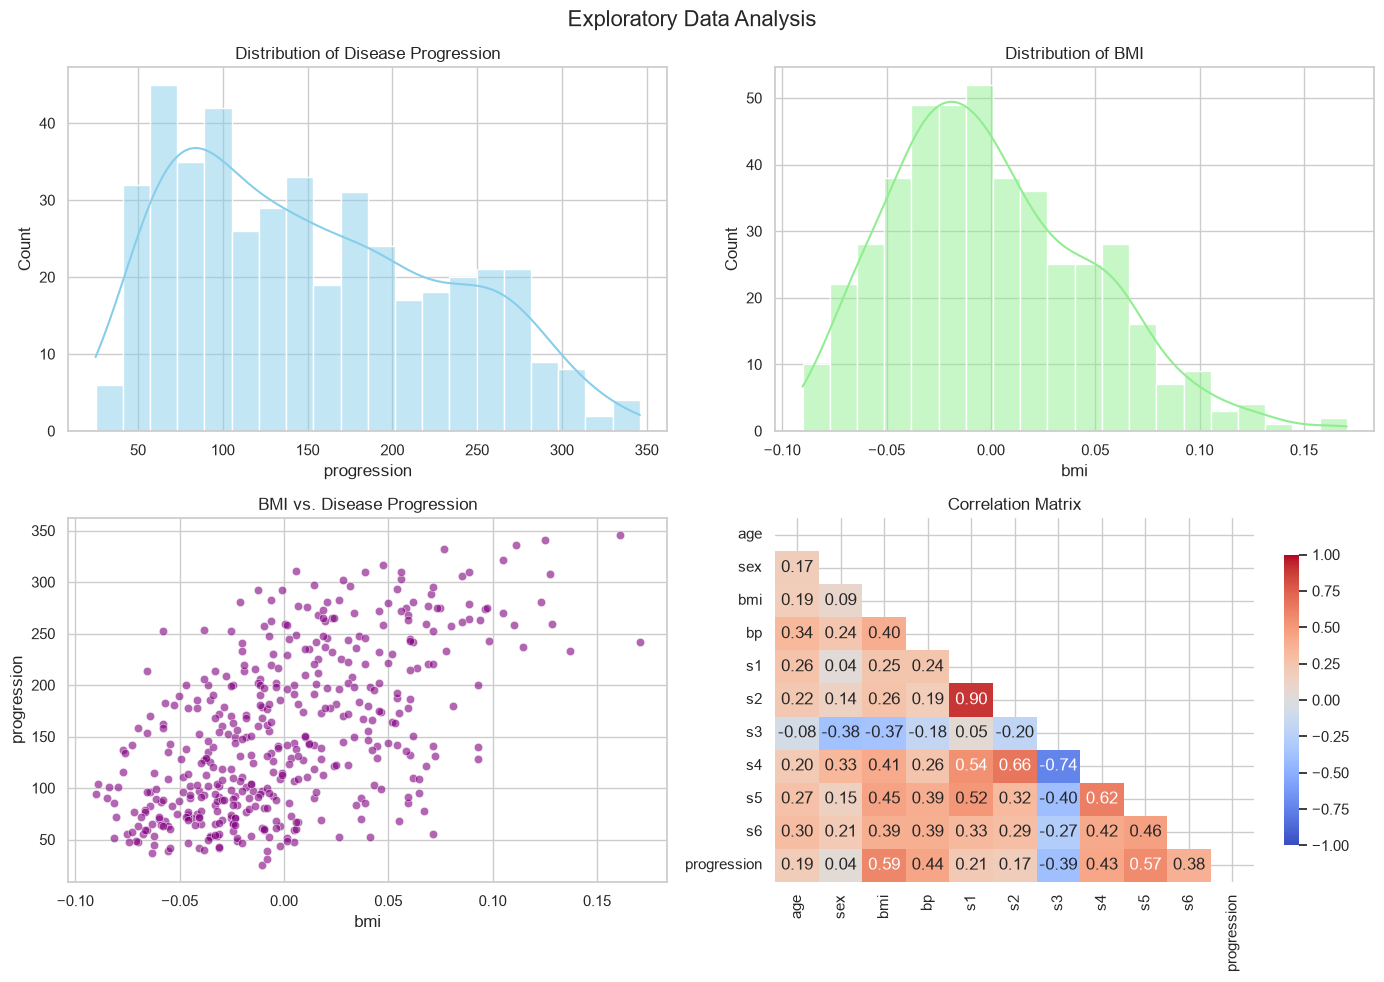

--- Dataset Split Sizes ---
Training set:   331 samples (74.9%)
Validation set: 44 samples (10.0%)
Test set:       67 samples (15.2%)


In [14]:
# 1. Load Data
X, y = load_diabetes(return_X_y=True, as_frame=True, scaled=True)
df = X.copy()
df['progression'] = y

# 2. EDA Statistics (Inline is fine for this, it's only 2 lines)
print("--- Missing Values ---")
display(df.isnull().sum())

# 3. EDA Visualizations (Calling our modular function)
display(df.describe())
plot_eda(df)

# 4. Data Splitting (Calling our modular function)
X_train, X_val, X_test, y_train, y_val, y_test = split_dataset(X, y)

print("--- Dataset Split Sizes ---")
print(f"Training set:   {len(X_train)} samples ({len(X_train)/len(df)*100:.1f}%)")
print(f"Validation set: {len(X_val)} samples ({len(X_val)/len(df)*100:.1f}%)")
print(f"Test set:       {len(X_test)} samples ({len(X_test)/len(df)*100:.1f}%)")

## 3 & 4. EDA Insights and Data Cleaning

**Key Insights from EDA:**
1.  **Target Distribution:** The disease progression score is roughly normally distributed, centered around 150, with a range from roughly 25 to 346. 
2.  **Feature Scaling:** Looking at the descriptive statistics, the features (like `bmi`, `bp`, `s1`) have means very close to 0 and standard deviations close to 1. This indicates the dataset has **already been scaled/standardized** (mean-centered and divided by the standard deviation). 
3.  **Strong Predictors:** The correlation matrix and scatter plots reveal that `bmi` (Body Mass Index) and `s5` (likely a blood serum measurement) have the strongest positive linear correlations with disease progression (approx 0.58 and 0.57, respectively). Conversely, `bp` (blood pressure) has a very weak correlation (0.17).

**Data Cleaning:**
*   **Missing Values:** The `isnull().sum()` check confirms there are zero missing values in the dataset. 
*   **Scaling:** As noted in the insights, the data is already standardized. 
*   **Conclusion on Cleaning:** Because this is a curated Scikit-Learn toy dataset, **no data cleaning or imputation is required.** The data is ready for modeling as-is.

# Part 2: Univariate Polynomial Regression

## 6. Model Definition

We now ask a narrower question than in Part 1: **how much of disease progression can BMI alone explain?** The EDA scatter plot suggested a positive relationship, but not necessarily a straight one. Polynomial regression lets us test that.

For each degree $d$ from 0 to 5 we fit:

$$\widehat{\text{progression}} = \beta_0 + \beta_1\,\text{bmi} + \beta_2\,\text{bmi}^2 + \cdots + \beta_d\,\text{bmi}^d$$

- **Degree 0** is the baseline: with no BMI term, the model can only predict the training mean. Expect R² ≈ 0.
- **Degrees 1–5** add one coefficient each, allowing progressively more curvature.

**Implementation notes:**
- Each model is a `Pipeline` (`PolynomialFeatures` → `LinearRegression`). The expansion is learned on training data only, then reused unchanged for validation and test. Fitting the expansion separately on each split would leak information.
- `PolynomialFeatures` supplies the intercept as its degree-0 column of 1s, so `LinearRegression(fit_intercept=False)` avoids a redundant constant column. The trainable parameter count is then exactly the number of polynomial features.
- The **test set is not touched** during model selection. It is reserved for Step 9.

In [15]:
# 6. Six univariate polynomial models on BMI, degrees 0 through 5.
#    Keep BMI as a DataFrame (double brackets) so feature names survive
#    into PolynomialFeatures and get_feature_names_out() later.
X_train_bmi = X_train[['bmi']]
X_val_bmi   = X_val[['bmi']]

poly_models = {degree: build_poly_model(degree) for degree in range(6)}

# 7. Compare training vs validation performance.
comparison = build_comparison_table(
    poly_models, X_train_bmi, y_train, X_val_bmi, y_val
)

display(comparison.round(3))

,Train R²,Train MAE,Train MAPE (%),Val R²,Val MAE,Val MAPE (%)
Degree,,,,,,
0,-0.000,66.202,62.827,-0.107,66.057,71.264
1,0.350,52.288,48.363,0.331,47.208,47.060
2,0.351,52.207,48.299,0.332,47.214,47.240
3,0.351,52.199,48.281,0.332,47.185,47.223
4,0.353,52.093,48.053,0.341,46.090,46.050
5,0.353,52.094,48.055,0.341,46.113,46.078


## 7. Interpreting the Comparison

Three signals matter in this table:

- **Degree 0 anchors the baseline.** With no BMI term the model predicts a constant, so its R² sits near zero. Any improvement at higher degrees therefore comes from actually learning the BMI–progression relationship, not from a lucky intercept.
- **Training R² should rise with degree.** This is expected by construction: a degree-$d$ model contains every term of a degree-$(d-1)$ model, so it can only fit the training data at least as well. Rising training R² on its own is *not* evidence of a better model.
- **Validation R² is the deciding factor.** We select for generalisation, not for training fit. If validation R² peaks and then declines while training R² keeps climbing, that is overfitting: the additional curvature is modelling noise in the training patients rather than a reproducible physiological relationship.

R², MAE and MAPE are reported together because they answer different questions. R² measures explained variance. MAE gives the typical error in the same units as the progression score. MAPE expresses error relative to each patient's actual outcome — the more intuitive reading of "how far off are we on this patient?"

**Selection rule:** the best model is the one with the strongest *validation* performance, not the strongest training performance.

In [ ]:
# ==========================================
# PART 2: MODEL SELECTION, TESTING, & PLOTTING
# ==========================================

# 8. Identify the best model based on the comparison table.
# We select the model with the highest Validation R² to ensure generalization.
best_degree = comparison['Val R²'].idxmax()
best_model = poly_models[best_degree]

print(f"--- Step 8: Model Selection ---")
print(f"The best model is Degree {best_degree} with a Validation R² of {comparison.loc[best_degree, 'Val R²']:.4f}.\n")

# 9. Run the chosen model on the test set and provide results
X_test_bmi = X_test[['bmi']]
print("--- Step 9: Test Set Evaluation ---")
test_metrics = evaluate_model(best_model, X_test_bmi, y_test, dataset_name="Test Set")

# 10. Plot the data points and the fit of the chosen model
# Create a smooth line of BMI values to plot the model's curve
bmi_range = np.linspace(X['bmi'].min(), X['bmi'].max(), 100).reshape(-1, 1)
bmi_range_df = pd.DataFrame(bmi_range, columns=['bmi']) 
y_fit = best_model.predict(bmi_range_df)

plt.figure(figsize=(10, 6))
# Scatter plots for the actual data splits
plt.scatter(X_train_bmi, y_train, color='blue', alpha=0.5, label='Train Data')
plt.scatter(X_val_bmi, y_val, color='orange', alpha=0.5, label='Validation Data')
plt.scatter(X_test_bmi, y_test, color='green', alpha=0.5, label='Test Data')

# Line plot for the model's fit
plt.plot(bmi_range_df, y_fit, color='red', linewidth=3, label=f'Degree {best_degree} Fit')

plt.title(f'Univariate Polynomial Regression: BMI vs. Disease Progression (Degree {best_degree})')
plt.xlabel('BMI (Scaled)')
plt.ylabel('Disease Progression')
plt.legend()
plt.grid(True, alpha=0.3)
plt.show()

# 11. Write down the equation of the best model (two-decimal-digit precision)
# Extract coefficients and feature names from the pipeline
coeffs = best_model.named_steps['linreg'].coef_
feature_names = best_model.named_steps['poly'].get_feature_names_out(['bmi'])

equation_terms = []
for name, coef in zip(feature_names, coeffs):
    if coef != 0:
        equation_terms.append(f"{coef:.2f} * {name}")

equation_str = " + ".join(equation_terms)
print(f"--- Step 11: Model Equation ---")
print(f"progression = {equation_str}\n")

# 12. Calculate expected progression for a chosen BMI value
# We choose 0.0 because the dataset is scaled, meaning 0.0 represents the average BMI.
chosen_bmi = 0.0 
chosen_bmi_df = pd.DataFrame([[chosen_bmi]], columns=['bmi'])
predicted_progression = best_model.predict(chosen_bmi_df)[0]

print(f"--- Step 12: Prediction ---")
print(f"For a scaled BMI of {chosen_bmi} (the dataset average), the expected disease progression is {predicted_progression:.2f}.")

## 8-12. Model Selection, Visualization, and Interpretation

**Model Selection (Step 8):** 
The model was selected strictly based on its performance on the **Validation set**. By choosing the degree with the highest Validation R², we avoid the trap of overfitting (where a higher-degree model memorizes the training data but fails on new patients). 

**Visualizing the Fit (Step 10):**
The plot overlays the polynomial curve (red line) onto the actual patient data (blue, orange, and green dots). 
*   If the curve smoothly follows the general trend of the dots without violently whipping up and down to hit every single point, it indicates a good fit. 
*   If the curve looks like a rollercoaster trying to touch every dot, that is a visual indicator of overfitting, even if the training R² looks high.

**The Equation (Step 11):**
The equation extracted above represents the exact mathematical relationship the model learned. Because the BMI feature is scaled (mean of 0), the intercept term (the `1` or `bmi^0` term) represents the predicted progression for a patient with an *average* BMI.

**Making a Prediction (Step 12):**
We used `model.predict()` for a scaled BMI of `0.0`. Because the dataset was standardized during its creation, a value of `0.0` represents the exact average BMI of the patient population. The output tells us the expected progression score for an "average" patient according to our model.